In [1]:
from google.colab import files
uploaded=files.upload()

Saving GermanCredit.xlsx to GermanCredit.xlsx


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df=pd.read_excel("GermanCredit.xlsx")

print(df.shape)
df.head()

(1000, 21)


,status,duration,credit_history,purpose,amount,savings,employment_duration,installment_rate,personal_status_sex,other_debtors,...,property,age,other_installment_plans,housing,number_credits,job,people_liable,telephone,foreign_worker,credit_risk
0,... < 100 DM,6,critical account/other credits existing,domestic appliances,1169,unknown/no savings account,... >= 7 years,4,male : single,none,...,real estate,67,none,own,2,skilled employee/official,1,yes,yes,1
1,0 <= ... < 200 DM,48,existing credits paid back duly till now,domestic appliances,5951,... < 100 DM,1 <= ... < 4 years,2,female : divorced/separated/married,none,...,real estate,22,none,own,1,skilled employee/official,1,no,yes,0
2,no checking account,12,critical account/other credits existing,retraining,2096,... < 100 DM,4 <= ... < 7 years,2,male : single,none,...,real estate,49,none,own,1,unskilled - resident,2,no,yes,1
3,... < 100 DM,42,existing credits paid back duly till now,radio/television,7882,... < 100 DM,4 <= ... < 7 years,2,male : single,guarantor,...,building society savings agreement/life insurance,45,none,for free,1,skilled employee/official,2,no,yes,1
4,... < 100 DM,24,delay in paying off in the past,car (new),4870,... < 100 DM,1 <= ... < 4 years,3,male : single,none,...,unknown/no property,53,none,for free,2,skilled employee/official,2,no,yes,0


In [3]:
## Check target
print(df["credit_risk"].value_counts())
print(df["credit_risk"].value_counts(normalize=True)*100)

credit_risk
1    700
0    300
Name: count, dtype: int64
credit_risk
1    70.0
0    30.0
Name: proportion, dtype: float64


In [4]:
## Remove EDA-only columns
df=df.drop(columns=["age_group","amount_group"],errors="ignore")
df

,status,duration,credit_history,purpose,amount,savings,employment_duration,installment_rate,personal_status_sex,other_debtors,...,property,age,other_installment_plans,housing,number_credits,job,people_liable,telephone,foreign_worker,credit_risk
0,... < 100 DM,6,critical account/other credits existing,domestic appliances,1169,unknown/no savings account,... >= 7 years,4,male : single,none,...,real estate,67,none,own,2,skilled employee/official,1,yes,yes,1
1,0 <= ... < 200 DM,48,existing credits paid back duly till now,domestic appliances,5951,... < 100 DM,1 <= ... < 4 years,2,female : divorced/separated/married,none,...,real estate,22,none,own,1,skilled employee/official,1,no,yes,0
2,no checking account,12,critical account/other credits existing,retraining,2096,... < 100 DM,4 <= ... < 7 years,2,male : single,none,...,real estate,49,none,own,1,unskilled - resident,2,no,yes,1
3,... < 100 DM,42,existing credits paid back duly till now,radio/television,7882,... < 100 DM,4 <= ... < 7 years,2,male : single,guarantor,...,building society savings agreement/life insurance,45,none,for free,1,skilled employee/official,2,no,yes,1
4,... < 100 DM,24,delay in paying off in the past,car (new),4870,... < 100 DM,1 <= ... < 4 years,3,male : single,none,...,unknown/no property,53,none,for free,2,skilled employee/official,2,no,yes,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,no checking account,12,existing credits paid back duly till now,radio/television,1736,... < 100 DM,4 <= ... < 7 years,3,female : divorced/separated/married,none,...,real estate,31,none,own,1,unskilled - resident,1,no,yes,1
996,... < 100 DM,30,existing credits paid back duly till now,car (used),3857,... < 100 DM,1 <= ... < 4 years,4,male : divorced/separated,none,...,building society savings agreement/life insurance,40,none,own,1,management/self-employed/highly qualified empl...,1,yes,yes,1
997,no checking account,12,existing credits paid back duly till now,domestic appliances,804,... < 100 DM,... >= 7 years,4,male : single,none,...,car or other,38,none,own,1,skilled employee/official,1,no,yes,1
998,... < 100 DM,45,existing credits paid back duly till now,domestic appliances,1845,... < 100 DM,1 <= ... < 4 years,4,male : single,none,...,unknown/no property,23,none,for free,1,skilled employee/official,1,yes,yes,0


In [5]:
## Separate X and y
## axis=1 means work with columns.
X=df.drop("credit_risk",axis=1)
y=df["credit_risk"]

In [6]:
## Identify categorical and numerical columns
numeric_cols=X.select_dtypes(include=np.number).columns.tolist()
categorical_cols=X.select_dtypes(exclude=np.number).columns.tolist()
print("Numerical:",numeric_cols)
print("Categorical:",categorical_cols)

Numerical: ['duration', 'amount', 'installment_rate', 'present_residence', 'age', 'number_credits', 'people_liable']
Categorical: ['status', 'credit_history', 'purpose', 'savings', 'employment_duration', 'personal_status_sex', 'other_debtors', 'property', 'other_installment_plans', 'housing', 'job', 'telephone', 'foreign_worker']


In [7]:
## Train-test split
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test=train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
    )
print("Training:",X_train.shape)
print("Testing:",X_test.shape)


Training: (800, 20)
Testing: (200, 20)


In [8]:
## preprocesing pipeline
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

numeric_pipeline=Pipeline([
    ("imputer",SimpleImputer(strategy="median")),
    ("scaler",StandardScaler())
])

categorical_pipeline=Pipeline([
    ("imputer",SimpleImputer(strategy="most_frequent")),
    ("encoder",OneHotEncoder())
])

preprocessor=ColumnTransformer([
    ("num",numeric_pipeline,numeric_cols),
    ("cat",categorical_pipeline,categorical_cols)
])
preprocessor


ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['duration', 'amount', 'installment_rate',
                                  'present_residence', 'age', 'number_credits',
                                  'people_liable']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder', OneHotEncoder())]),
                                 ['status', 'credit_history', 'purpose',
                                  'savings', 'employment_duration',
                                  'personal_status_sex', 'other_debtors',
                                  'property', 'other_installment_plans',
                                  'housing', 'job', 'telephone',
                                  'foreign_worker'])])

In [9]:
## Basic ML — Logistic Regression
from sklearn.linear_model import LogisticRegression

logistic_model=Pipeline([
    ("preprocessor",preprocessor),
    ("model",LogisticRegression(max_iter=1000))
])
logistic_model.fit(X_train,y_train)
y_pred=logistic_model.predict(X_test)
y_prob=logistic_model.predict_proba(X_test)[:,1]

In [10]:
## evaluate logistic regression
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,roc_auc_score

print("Accuracy:",accuracy_score(y_test,y_pred))
print("Precision:",precision_score(y_test,y_pred))
print("Recall:",recall_score(y_test,y_pred))
print("F1 Score:",f1_score(y_test,y_pred))
print("ROC-AUC:",roc_auc_score(y_test,y_prob))

Accuracy: 0.705
Precision: 0.7755102040816326
Recall: 0.8142857142857143
F1 Score: 0.794425087108014
ROC-AUC: 0.7594047619047619


In [11]:
##
from sklearn.metrics import classification_report

print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.51      0.45      0.48        60
           1       0.78      0.81      0.79       140

    accuracy                           0.70       200
   macro avg       0.64      0.63      0.64       200
weighted avg       0.70      0.70      0.70       200



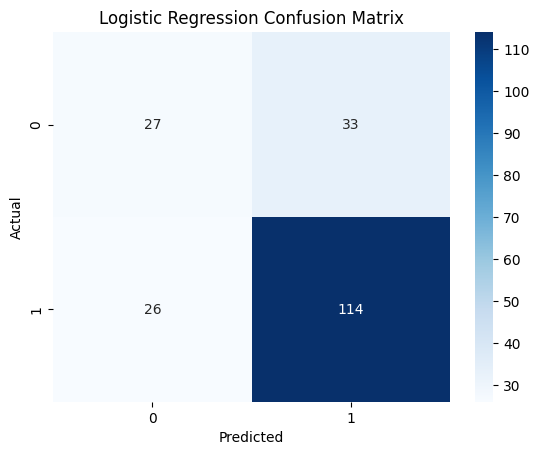

In [12]:
from sklearn.metrics import confusion_matrix

cm=confusion_matrix(y_test,y_pred)
sns.heatmap(cm,annot=True,fmt="d",cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

In [13]:
## fmt means format.
## "d" means integer (whole number).

In [14]:
## decision tree
from sklearn.tree import DecisionTreeClassifier

dt_model=Pipeline([
    ("preprocessor",preprocessor),
    ("model",DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ))
])

dt_model.fit(X_train,y_train)
dt_pred=dt_model.predict(X_test)
dt_prob=dt_model.predict_proba(X_test)[:,1]

In [15]:
## evaluate dt
print("Accuracy:",accuracy_score(y_test,dt_pred))
print("Precision:",precision_score(y_test,dt_pred))
print("Recall:",recall_score(y_test,dt_pred))
print("F1:",f1_score(y_test,dt_pred))
print("ROC-AUC:",roc_auc_score(y_test,dt_prob))

Accuracy: 0.685
Precision: 0.7251461988304093
Recall: 0.8857142857142857
F1: 0.797427652733119
ROC-AUC: 0.6798809523809524


In [16]:
## random forest
from sklearn.ensemble import RandomForestClassifier

rf_model=Pipeline([
    ("preprocessor",preprocessor),
    ("model",RandomForestClassifier(
        n_estimators=300,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train,y_train)
rf_pred=rf_model.predict(X_test)
rf_prob=rf_model.predict_proba(X_test)[:,1]

In [17]:
## evaluate rf
print("Accuracy:",accuracy_score(y_test,rf_pred))
print("Precision:",precision_score(y_test,rf_pred))
print("Recall:",recall_score(y_test,rf_pred))
print("F1:",f1_score(y_test,rf_pred))
print("ROC-AUC:",roc_auc_score(y_test,rf_prob))

Accuracy: 0.78
Precision: 0.7962962962962963
Recall: 0.9214285714285714
F1: 0.8543046357615894
ROC-AUC: 0.8036904761904763


In [18]:
## compare basics models in df
results=pd.DataFrame({
    "Model":["LogisticRegression","Decision Tree","Random Forest"],
    "Accuracy":[
        accuracy_score(y_test,y_pred),
        accuracy_score(y_test,dt_pred),
        accuracy_score(y_test,rf_pred)
    ],
    "Precision":[
        precision_score(y_test,y_pred),
        precision_score(y_test,dt_pred),
        precision_score(y_test,rf_pred)
    ],
    "Recall":[
        recall_score(y_test,y_pred),
        recall_score(y_test,dt_pred),
        recall_score(y_test,rf_pred)
    ],
    "F1 Score":[
        f1_score(y_test,y_pred),
        f1_score(y_test,dt_pred),
        f1_score(y_test,rf_pred)
    ],
    "ROC-AUC":[
        roc_auc_score(y_test,y_prob),
        roc_auc_score(y_test,dt_prob),
        roc_auc_score(y_test,rf_prob)
    ]
})
results

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,LogisticRegression,0.705,0.775510,0.814286,0.794425,0.759405
1,Decision Tree,0.685,0.725146,0.885714,0.797428,0.679881
2,Random Forest,0.780,0.796296,0.921429,0.854305,0.803690


In [19]:
## Gradient Boosting
## Gradient Boosting builds trees sequentially, where later trees try to correct previous mistakes.

from sklearn.ensemble import GradientBoostingClassifier
gb_model=Pipeline([
    ("preprocessor",preprocessor),
    ("model",GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ))
])
gb_model.fit(X_train,y_train)
gb_pred=gb_model.predict(X_test)
gb_prob=gb_model.predict_proba(X_test)[:,1]

In [20]:
## evaluate gb
print("Gradient Boosting")
print("Accuracy:",accuracy_score(y_test,gb_pred))
print("Precision:",precision_score(y_test,gb_pred))
print("Recall:",recall_score(y_test,gb_pred))
print("F1:",f1_score(y_test,gb_pred))

Gradient Boosting
Accuracy: 0.76
Precision: 0.815068493150685
Recall: 0.85
F1: 0.8321678321678322


In [21]:
## xgboost
from xgboost import XGBClassifier

xgb_model=Pipeline([
    ("preprocessor",preprocessor),
    ("model",XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42
    ))
])

In [22]:
## subsample = how many ROWS each tree sees
## subsample=0.8, Each tree uses 80% of the training rows.
## Colsample → Columns, 80% of features
## Log Loss penalizes confident wrong predictions heavily.

In [23]:
## train & predict xgb
xgb_model.fit(X_train,y_train)
xgb_pred=xgb_model.predict(X_test)
xgb_prob=xgb_model.predict_proba(X_test)[:,1]

In [24]:
## evaluate
print("XGBoost")
print("Accuracy:",accuracy_score(y_test,xgb_pred))
print("Precision:",precision_score(y_test,xgb_pred))
print("Recall:",recall_score(y_test,xgb_pred))
print("F1:",f1_score(y_test,xgb_pred))
print("ROC-AUC:",roc_auc_score(y_test,xgb_prob))

XGBoost
Accuracy: 0.73
Precision: 0.7905405405405406
Recall: 0.8357142857142857
F1: 0.8125
ROC-AUC: 0.7598809523809523


In [25]:
## lightgbm
from lightgbm import LGBMClassifier

lgbm_model=Pipeline([
    ("preprocessor",preprocessor),
    ("model",LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        num_leaves=31,
        max_depth=-1,
        random_state=42,
        verbosity=-1
    ))
])

In [26]:
## verbosity=-1, Don't display LightGBM's unnecessary training messages/warnings in the output.

In [27]:
## train and predict lgbm
lgbm_model.fit(X_train,y_train)

lgbm_pred=lgbm_model.predict(X_test)
lgbm_prob=lgbm_model.predict_proba(X_test)[:,1]

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [28]:
## evaluate
print("LightGBM")
print("Accuracy:",accuracy_score(y_test,lgbm_pred))
print("Precision:",precision_score(y_test,lgbm_pred))
print("Recall:",recall_score(y_test,lgbm_pred))
print("F1:",f1_score(y_test,lgbm_pred))
print("ROC-AUC:",roc_auc_score(y_test,lgbm_prob))

LightGBM
Accuracy: 0.74
Precision: 0.7933333333333333
Recall: 0.85
F1: 0.8206896551724138
ROC-AUC: 0.7522619047619048


In [29]:
## compare all models
results=pd.DataFrame({
    "Model":["Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting",
        "XGBoost",
        "LightGBM"
        ],
    "Accuracy":[
        accuracy_score(y_test,y_pred),
        accuracy_score(y_test,dt_pred),
        accuracy_score(y_test,rf_pred),
        accuracy_score(y_test,gb_pred),
        accuracy_score(y_test,xgb_pred),
        accuracy_score(y_test,lgbm_pred)
    ],
    "Precision":[
        precision_score(y_test,y_pred),
        precision_score(y_test,dt_pred),
        precision_score(y_test,rf_pred),
        precision_score(y_test,gb_pred),
        precision_score(y_test,xgb_pred),
        precision_score(y_test,lgbm_pred)
    ],
    "Recall":[
         recall_score(y_test,y_pred),
        recall_score(y_test,dt_pred),
        recall_score(y_test,rf_pred),
        recall_score(y_test,gb_pred),
        recall_score(y_test,xgb_pred),
        recall_score(y_test,lgbm_pred)
    ],
    "F1 Score":[
        f1_score(y_test,y_pred),
        f1_score(y_test,dt_pred),
        f1_score(y_test,rf_pred),
        f1_score(y_test,gb_pred),
        f1_score(y_test,xgb_pred),
        f1_score(y_test,lgbm_pred)
    ],
    "ROC-AUC":[
        roc_auc_score(y_test,y_prob),
        roc_auc_score(y_test,dt_prob),
        roc_auc_score(y_test,rf_prob),
        roc_auc_score(y_test,gb_prob),
        roc_auc_score(y_test,xgb_prob),
        roc_auc_score(y_test,lgbm_prob)
    ]
})
results.sort_values("ROC-AUC",ascending=False)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
2,Random Forest,0.780,0.796296,0.921429,0.854305,0.803690
3,Gradient Boosting,0.760,0.815068,0.850000,0.832168,0.779881
4,XGBoost,0.730,0.790541,0.835714,0.812500,0.759881
0,Logistic Regression,0.705,0.775510,0.814286,0.794425,0.759405
5,LightGBM,0.740,0.793333,0.850000,0.820690,0.752262
1,Decision Tree,0.685,0.725146,0.885714,0.797428,0.679881


In [30]:
## hyperparameter tuning
from sklearn.model_selection import RandomizedSearchCV

## RandomizedSearchCV automatically tries different combinations.
## create parameter combinations with proper pipeline double-underscore prefix
param_grid={
    "model__n_estimators":[100,200,300,500],
    "model__learning_rate":[0.01,0.03,0.05,0.1],
    "model__max_depth":[3,4,5,6],
    "model__subsample":[0.7,0.8,1.0],
    "model__colsample_bytree":[0.7,0.8,1.0]
}

In [31]:
## "model__n_estimators":[100,200,300,500]
## Number of trees used by XGBoost.
## 100 → smaller model.
## 200 → more trees.
## 300 → stronger model.
## 500 → larger model.

## "model__learning_rate":[0.01,0.03,0.05,0.1]
## Controls how much each tree contributes.
## 0.01 → very slow learning.
## 0.03 → slow learning.
## 0.05 → moderate learning.
## 0.1 → faster learning.

## "model__subsample":[0.7,0.8,1.0]
## Controls how many rows are used for each tree.
## 0.7 → 70% of rows.
## 0.8 → 80% of rows.
## 1.0 → 100% of rows.

## same for model_colsample ,columns

In [32]:
## Create RandomizedSearchCV
search=RandomizedSearchCV(
    xgb_model,
    param_distributions=param_grid,
    n_iter=15,
    scoring="roc_auc",
    cv=5,
    random_state=42,
    n_jobs=-1
)

In [33]:
## param_distributions=param_grid, Tells RandomizedSearchCV which parameters it should try.
## cv=5, Uses 5-fold cross-validation,
## for eg.cv;
## Fold 1 → Train 4 parts, Validate 1
## Fold 2 → Train 4 parts, Validate 1
## Fold 3 → Train 4 parts, Validate 1
## Fold 4 → Train 4 parts, Validate 1
## Fold 5 → Train 4 parts, Validate 1

In [34]:
## Start Hyperparameter Tuning
search.fit(X_train,y_train)

print("Best Parameters:")
print(search.best_params_)

print("Best CV ROC-AUC:")
print(search.best_score_)

Best Parameters:
{'model__subsample': 0.7, 'model__n_estimators': 300, 'model__max_depth': 4, 'model__learning_rate': 0.01, 'model__colsample_bytree': 1.0}
Best CV ROC-AUC:
0.7959449404761905


In [40]:
## best models
best_model=search.best_estimator_
best_model

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['duration', 'amount',
                                                   'installment_rate',
                                                   'present_residence', 'age',
                                                   'number_credits',
                                                   'people_liable']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   O...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.01,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=4, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=300, n_jobs=None,
                               num_parallel_tree=None, ...))])

In [41]:
## predict
best_pred=best_model.predict(X_test)
best_prob=best_model.predict_proba(X_test)[:,1]

In [42]:
## run best
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,roc_auc_score

print("Tuned XGBoost")
print("Accuracy:",accuracy_score(y_test,best_pred))
print("Precision:",precision_score(y_test,best_pred))
print("Recall:",recall_score(y_test,best_pred))
print("F1:",f1_score(y_test,best_pred))
print("ROC-AUC:",roc_auc_score(y_test,best_prob))

Tuned XGBoost
Accuracy: 0.725
Precision: 0.7707006369426752
Recall: 0.8642857142857143
F1: 0.8148148148148148
ROC-AUC: 0.7725000000000001
